# 02 Guided modes: the S02 lecture examples

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Photonic-Architecture-Laboratories/elec438tools/blob/main/tutorials/02_guided_modes.ipynb)

The two examples from the *S02 Guided Modes* slides, solved with `elec438tools`: a 1 um thick slab and a 2 x 1 um rectangular core, both of index 1.444 in air, at 1.55 um, in a 3 x 4 um simulation region with metal boundaries. The values on the slides are printed alongside for comparison.

## How to use this notebook

**In Google Colab (recommended: nothing to install)**

1. Open the course copy: https://colab.research.google.com/github/Photonic-Architecture-Laboratories/elec438tools/blob/main/tutorials/02_guided_modes.ipynb
   You can run and even edit this copy, but nothing you do is kept: Colab cannot save it back to GitHub, so your changes disappear when you close the tab.
2. To keep your work, make your own copy first: **File → Save a copy in Drive**. Colab opens the copy ("Copy of 02_guided_modes.ipynb"), which is saved in your Google Drive under *Colab Notebooks*. Work in that copy from now on.
3. Run the cells in order with **Shift + Enter**, or all at once with **Runtime → Run all**. The first code cell installs `elec438tools` (about 20 s). Colab forgets installed packages when its runtime restarts, so that cell runs again in each new session.
4. Keep the default **CPU** runtime. The solver does not use a GPU, so a GPU runtime will not make it faster.

**On your own computer:** run `pip install git+https://github.com/Photonic-Architecture-Laboratories/elec438tools.git` once, then open the notebook in Jupyter or VS Code.

**Updates:** if the course copy changes during the semester, open the link again and save a new copy; your old copy keeps your own work.

In [1]:
# Setup: installs elec438tools if it is missing (on Colab this takes ~20 s)
import importlib.util, subprocess, sys
if importlib.util.find_spec("elec438tools") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "git+https://github.com/Photonic-Architecture-Laboratories/elec438tools.git"])

import numpy as np
import matplotlib.pyplot as plt
import elec438tools as et

## Slab: 1 um thick, n = 1.444, uniform in x

On the slides the slab fills the region in $x$, so the metal boundaries at $x = \pm 1.5$ um also act on it: modes 2 to 6 have the same vertical profile as mode 1 but form standing waves along $x$ between these two boundaries.

In [2]:
sim = et.ModeSolver(region_width=3.0, region_height=4.0, dx=0.02, background="air")
sim.add(et.Layer(-0.5, 0.5, 1.444))
slab_modes = sim.solve(1.55, num_modes=8)
slides = [1.347850, 1.322865, 1.283040, 1.244908, 1.202506, 1.102848, 1.072984]
for m, ref in zip(slab_modes, slides):
    print(f"mode {m.index + 1}:  neff {m.neff.real:.6f}   slides {ref:.6f}   TE fraction {100*m.te_fraction:.0f} %")

mode 1:  neff 1.347797   slides 1.347850   TE fraction 100 %
mode 2:  neff 1.322808   slides 1.322865   TE fraction 100 %
mode 3:  neff 1.282999   slides 1.283040   TE fraction 1 %
mode 4:  neff 1.244850   slides 1.244908   TE fraction 100 %
mode 5:  neff 1.202462   slides 1.202506   TE fraction 3 %
mode 6:  neff 1.102782   slides 1.102848   TE fraction 100 %
mode 7:  neff 1.072824   slides 1.072984   TE fraction 100 %


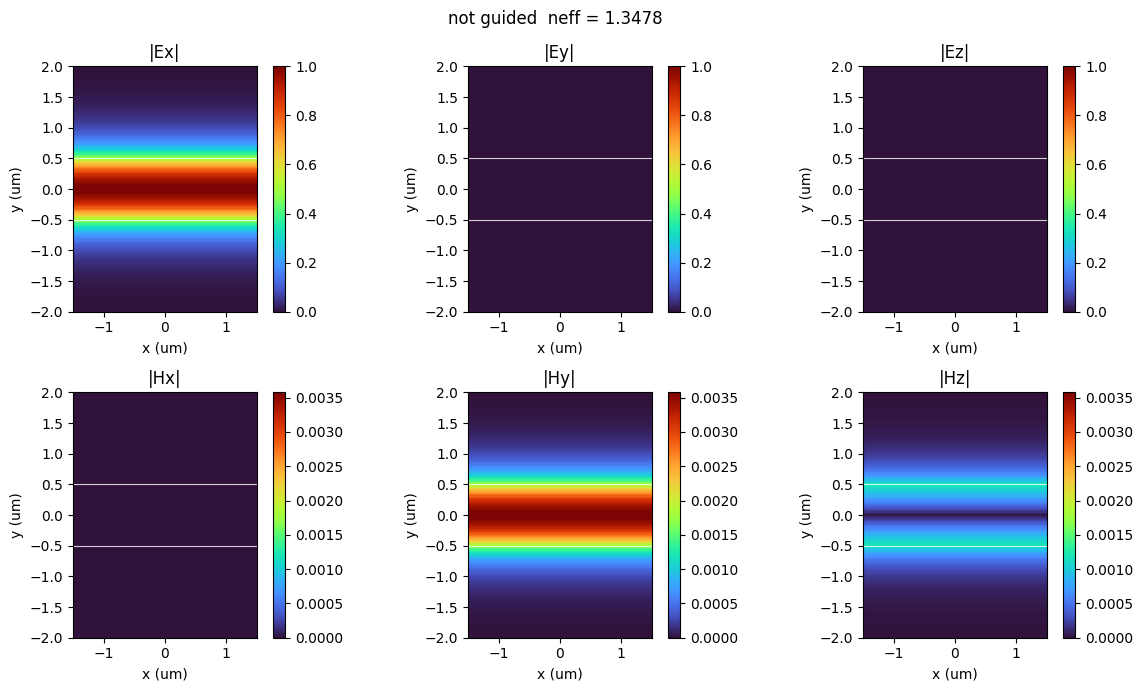

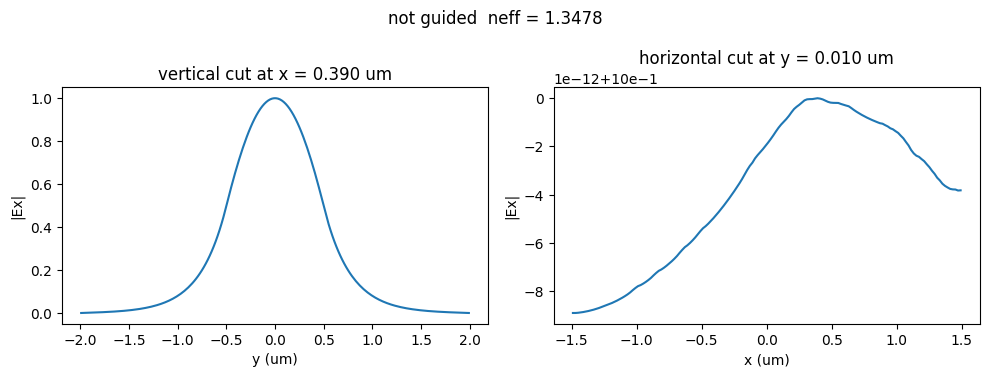

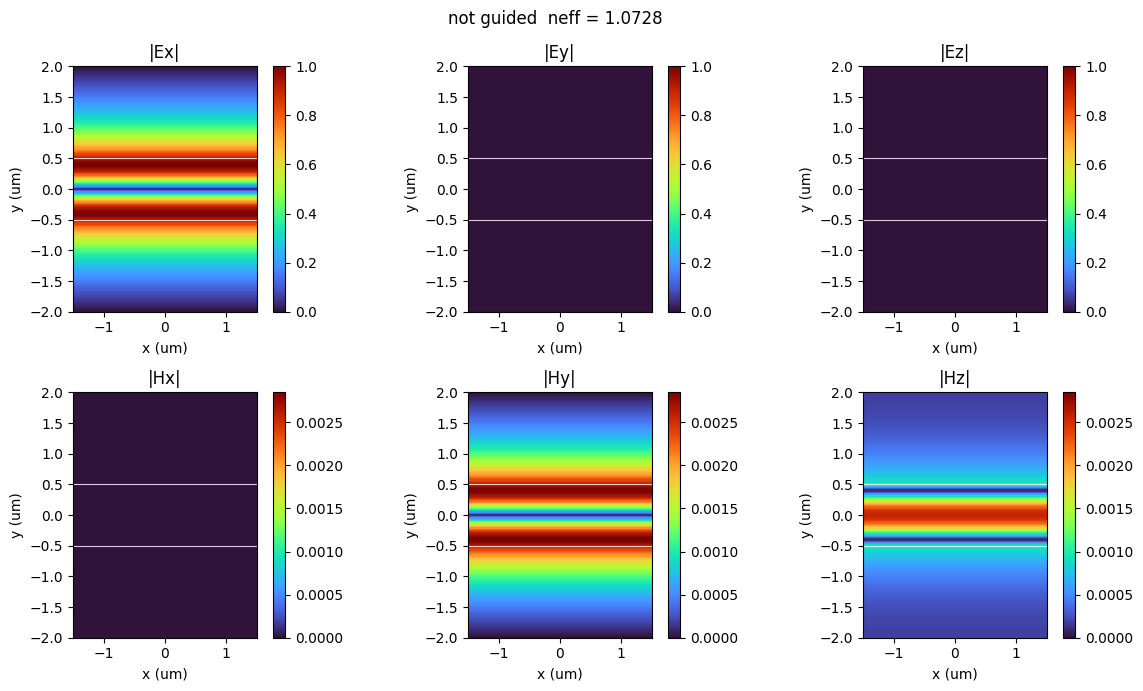

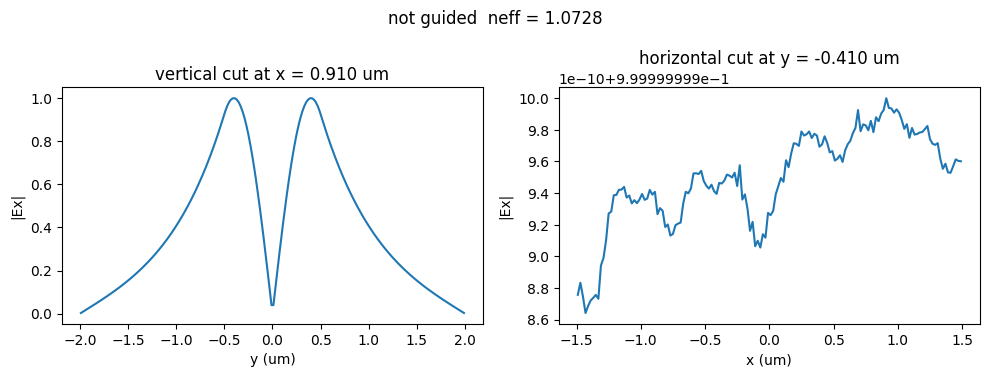

In [3]:
for k in (0, 6):           # mode A and mode B of the slides
    slab_modes[k].plot_fields()
    slab_modes[k].plot_slice("Ex")

## Rectangle: 2 x 1 um core, n = 1.444

C:\Users\W4T\AppData\Local\Temp\ipykernel_55820\3043730025.py:4: UserWarning: TE1: 2.9% of its |E|^2 lies along the metal boundaries, so the boundaries change its neff. Enlarge region_width / region_height.
  modes = sim.solve(1.55, num_modes=8)
C:\Users\W4T\AppData\Local\Temp\ipykernel_55820\3043730025.py:4: UserWarning: TE2: 2.2% of its |E|^2 lies along the metal boundaries, so the boundaries change its neff. Enlarge region_width / region_height.
  modes = sim.solve(1.55, num_modes=8)
C:\Users\W4T\AppData\Local\Temp\ipykernel_55820\3043730025.py:4: UserWarning: TE3: 13.0% of its |E|^2 lies along the metal boundaries, so the boundaries change its neff. Enlarge region_width / region_height.
  modes = sim.solve(1.55, num_modes=8)


wavelength 1.55 um; guided means Re(neff) > 1.0000 (cladding index, or slab-mode index for a rib)
  # name                    neff  loss(dB/cm)  TE frac  Aeff(um2)  guided
  0 TE0                 1.303960            0    99.9%      1.857     yes
  1 TM0                 1.271272            0     0.5%      2.238     yes
  2 TE1                 1.176573            0    99.0%      2.826     yes
  3 TM1                 1.155587            0     3.3%      2.436     yes
  4 TE2                 1.029538            0    99.0%      4.051     yes
  5 TE3                 1.020241            0    95.8%      3.748     yes
  6 -                   0.996272            0     1.4%      5.714      no
  7 -                   0.958465            0    39.1%      4.113      no

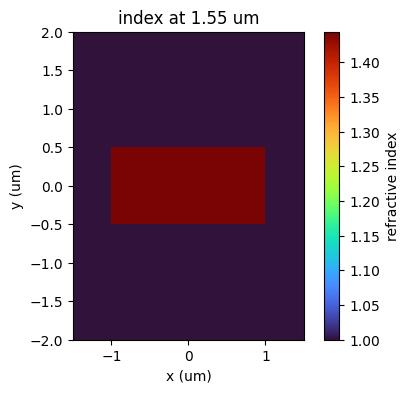

In [4]:
sim = et.ModeSolver(region_width=3.0, region_height=4.0, dx=0.02, background="air")
sim.add(et.Rect(width=2.0, height=1.0, material=1.444))
sim.plot_index()
modes = sim.solve(1.55, num_modes=8)
modes

In [5]:
slides = {"TE0": 1.304020, "TM0": 1.271321, "TE1": 1.176642, "TM1": 1.155666, "TE2": 1.029682}
for name, ref in slides.items():
    print(f"{name}:  neff {modes[name].neff.real:.6f}   slides {ref:.6f}")

TE0:  neff 1.303960   slides 1.304020
TM0:  neff 1.271272   slides 1.271321
TE1:  neff 1.176573   slides 1.176642
TM1:  neff 1.155587   slides 1.155666
TE2:  neff 1.029538   slides 1.029682


The warnings say that in the slides' region the fields of the higher-order modes have not decayed where the simulation boundaries are placed. Enlarging the region shifts their $n_\mathrm{eff}$ in the 3rd or 4th decimal place.

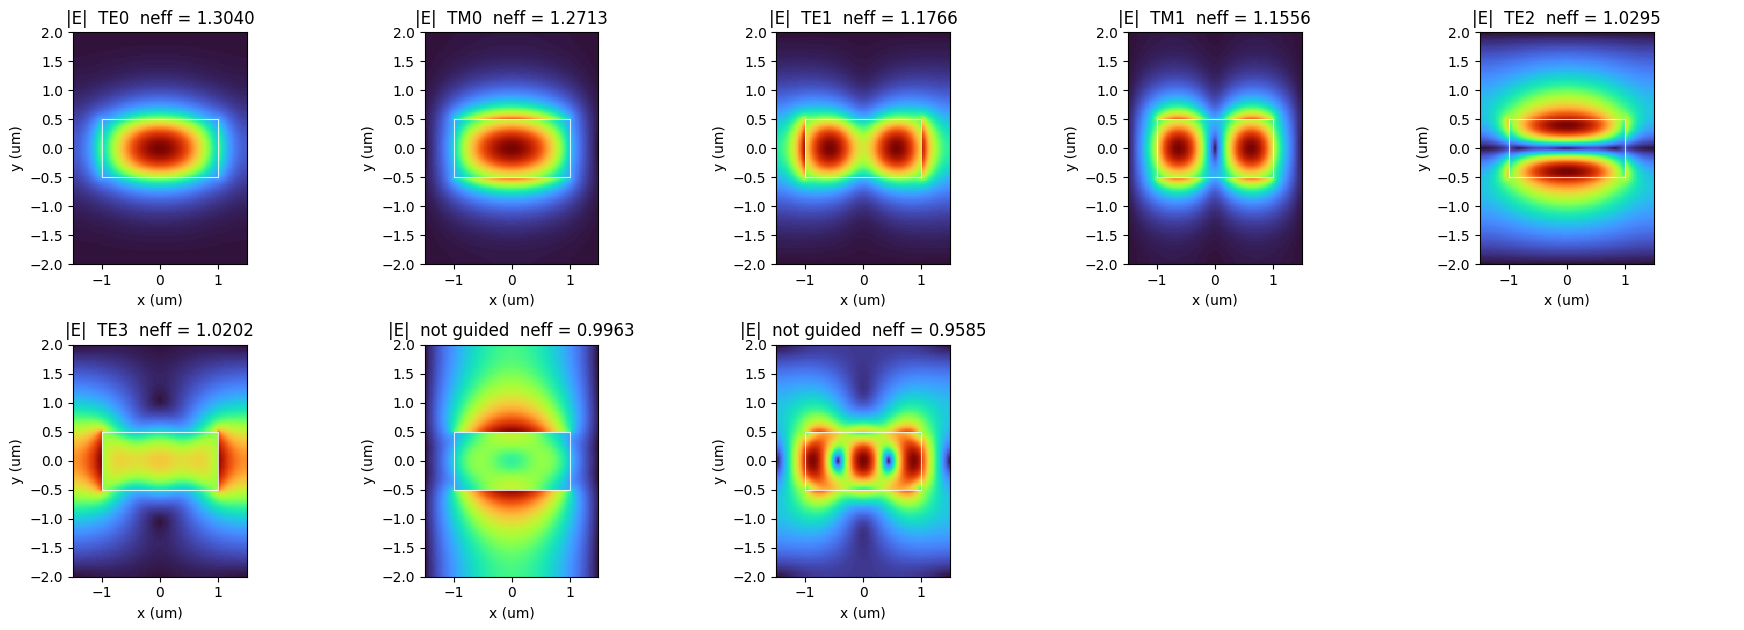

In [6]:
modes.plot("E", max_cols=5);

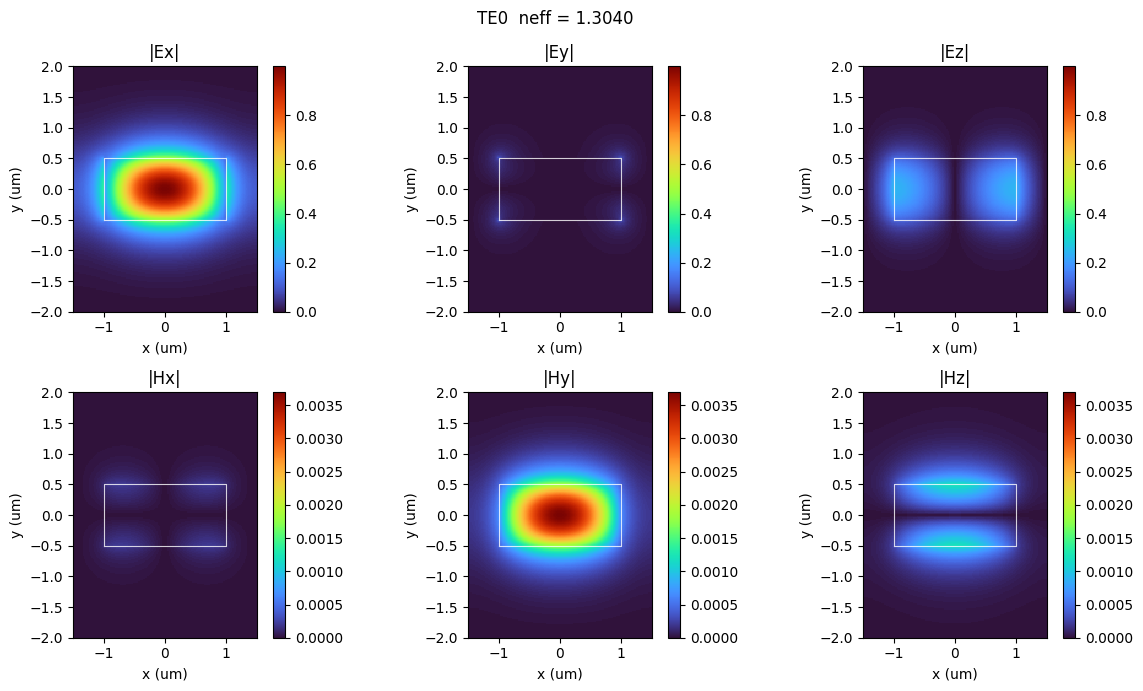

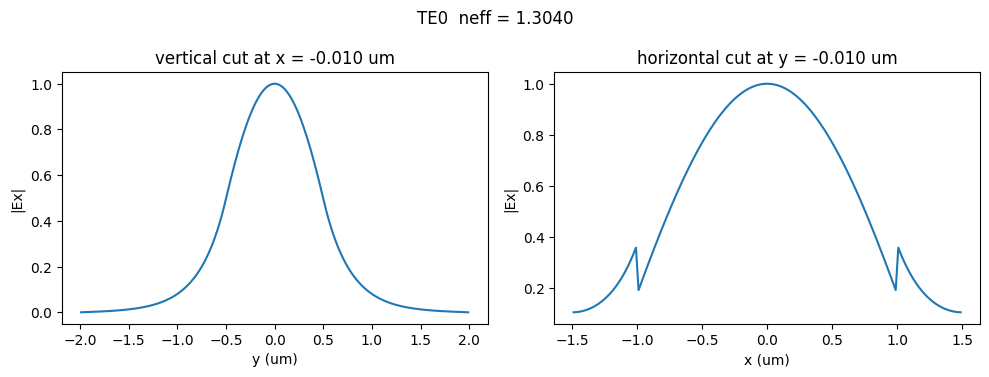

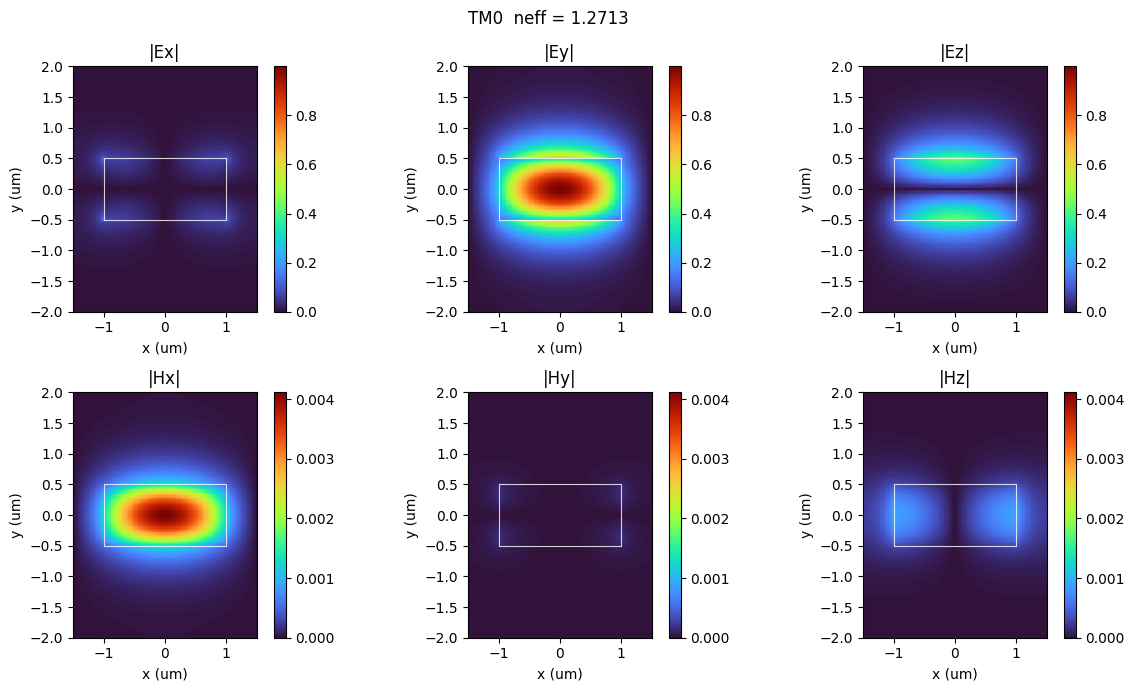

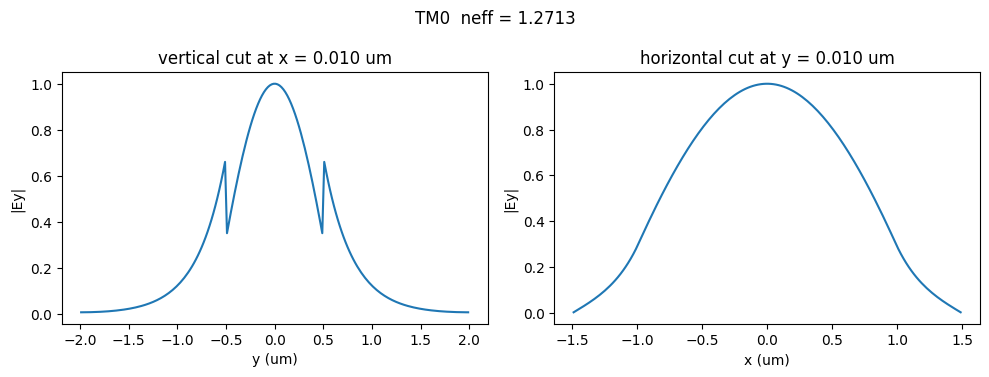

In [7]:
for name in ("TE0", "TM0"):
    modes[name].plot_fields()
    modes[name].plot_slice("Ex" if name == "TE0" else "Ey")